In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from sklearn.preprocessing import LabelEncoder
import tqdm
import pandas as pd
from torchvision.datasets import EMNIST
from torch.utils.data import DataLoader, random_split
# from resnet import ResNet18
import cv2
import numpy as np
import os
from PIL import Image, ImageFilter
import random

# Reading data

In [ ]:
dir = "./dataset_ocr/Train/"
import string
train_data = []
img_size = 32
ignore = string.digits + string.punctuation
for i in os.listdir(dir):
    if i in ignore:
        continue
    sub_directory = os.path.join(dir,i)
    for j in os.listdir(sub_directory):
        # img = cv2.imread(os.path.join(sub_directory, j), 0)
        # print(img.shape)
        train_data.append([os.path.join(sub_directory, j), i])


val_dir = "./dataset_ocr/Validation/"
val_data = []
img_size = 32
for i in os.listdir(val_dir):
    if i in ignore:
        continue
    sub_directory = os.path.join(val_dir,i)
    for j in os.listdir(sub_directory):
        val_data.append([os.path.join(sub_directory, j), i])

In [ ]:
random.shuffle(train_data)
random.shuffle(val_data)

In [ ]:
pd.DataFrame(train_data, columns=["image", "label"]).to_csv("./dataset_train_non_num.csv")

In [ ]:
pd.DataFrame(val_data, columns=["image", "label"]).to_csv("./dataset_val_non_num.csv")

In [31]:
len(train_data)

335102

In [32]:
batch_size = 256
num_epochs = 60

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

df_train = pd.read_csv("./dataset_train.csv")
df_val = pd.read_csv("./dataset_val.csv")

label_counts = df_train["label"].value_counts()
label_encoder = LabelEncoder()

# df_train["label"] = label_encoder.fit_transform(df_train["label"])

num_classes = df_train["label"].nunique()

In [ ]:
num_classes

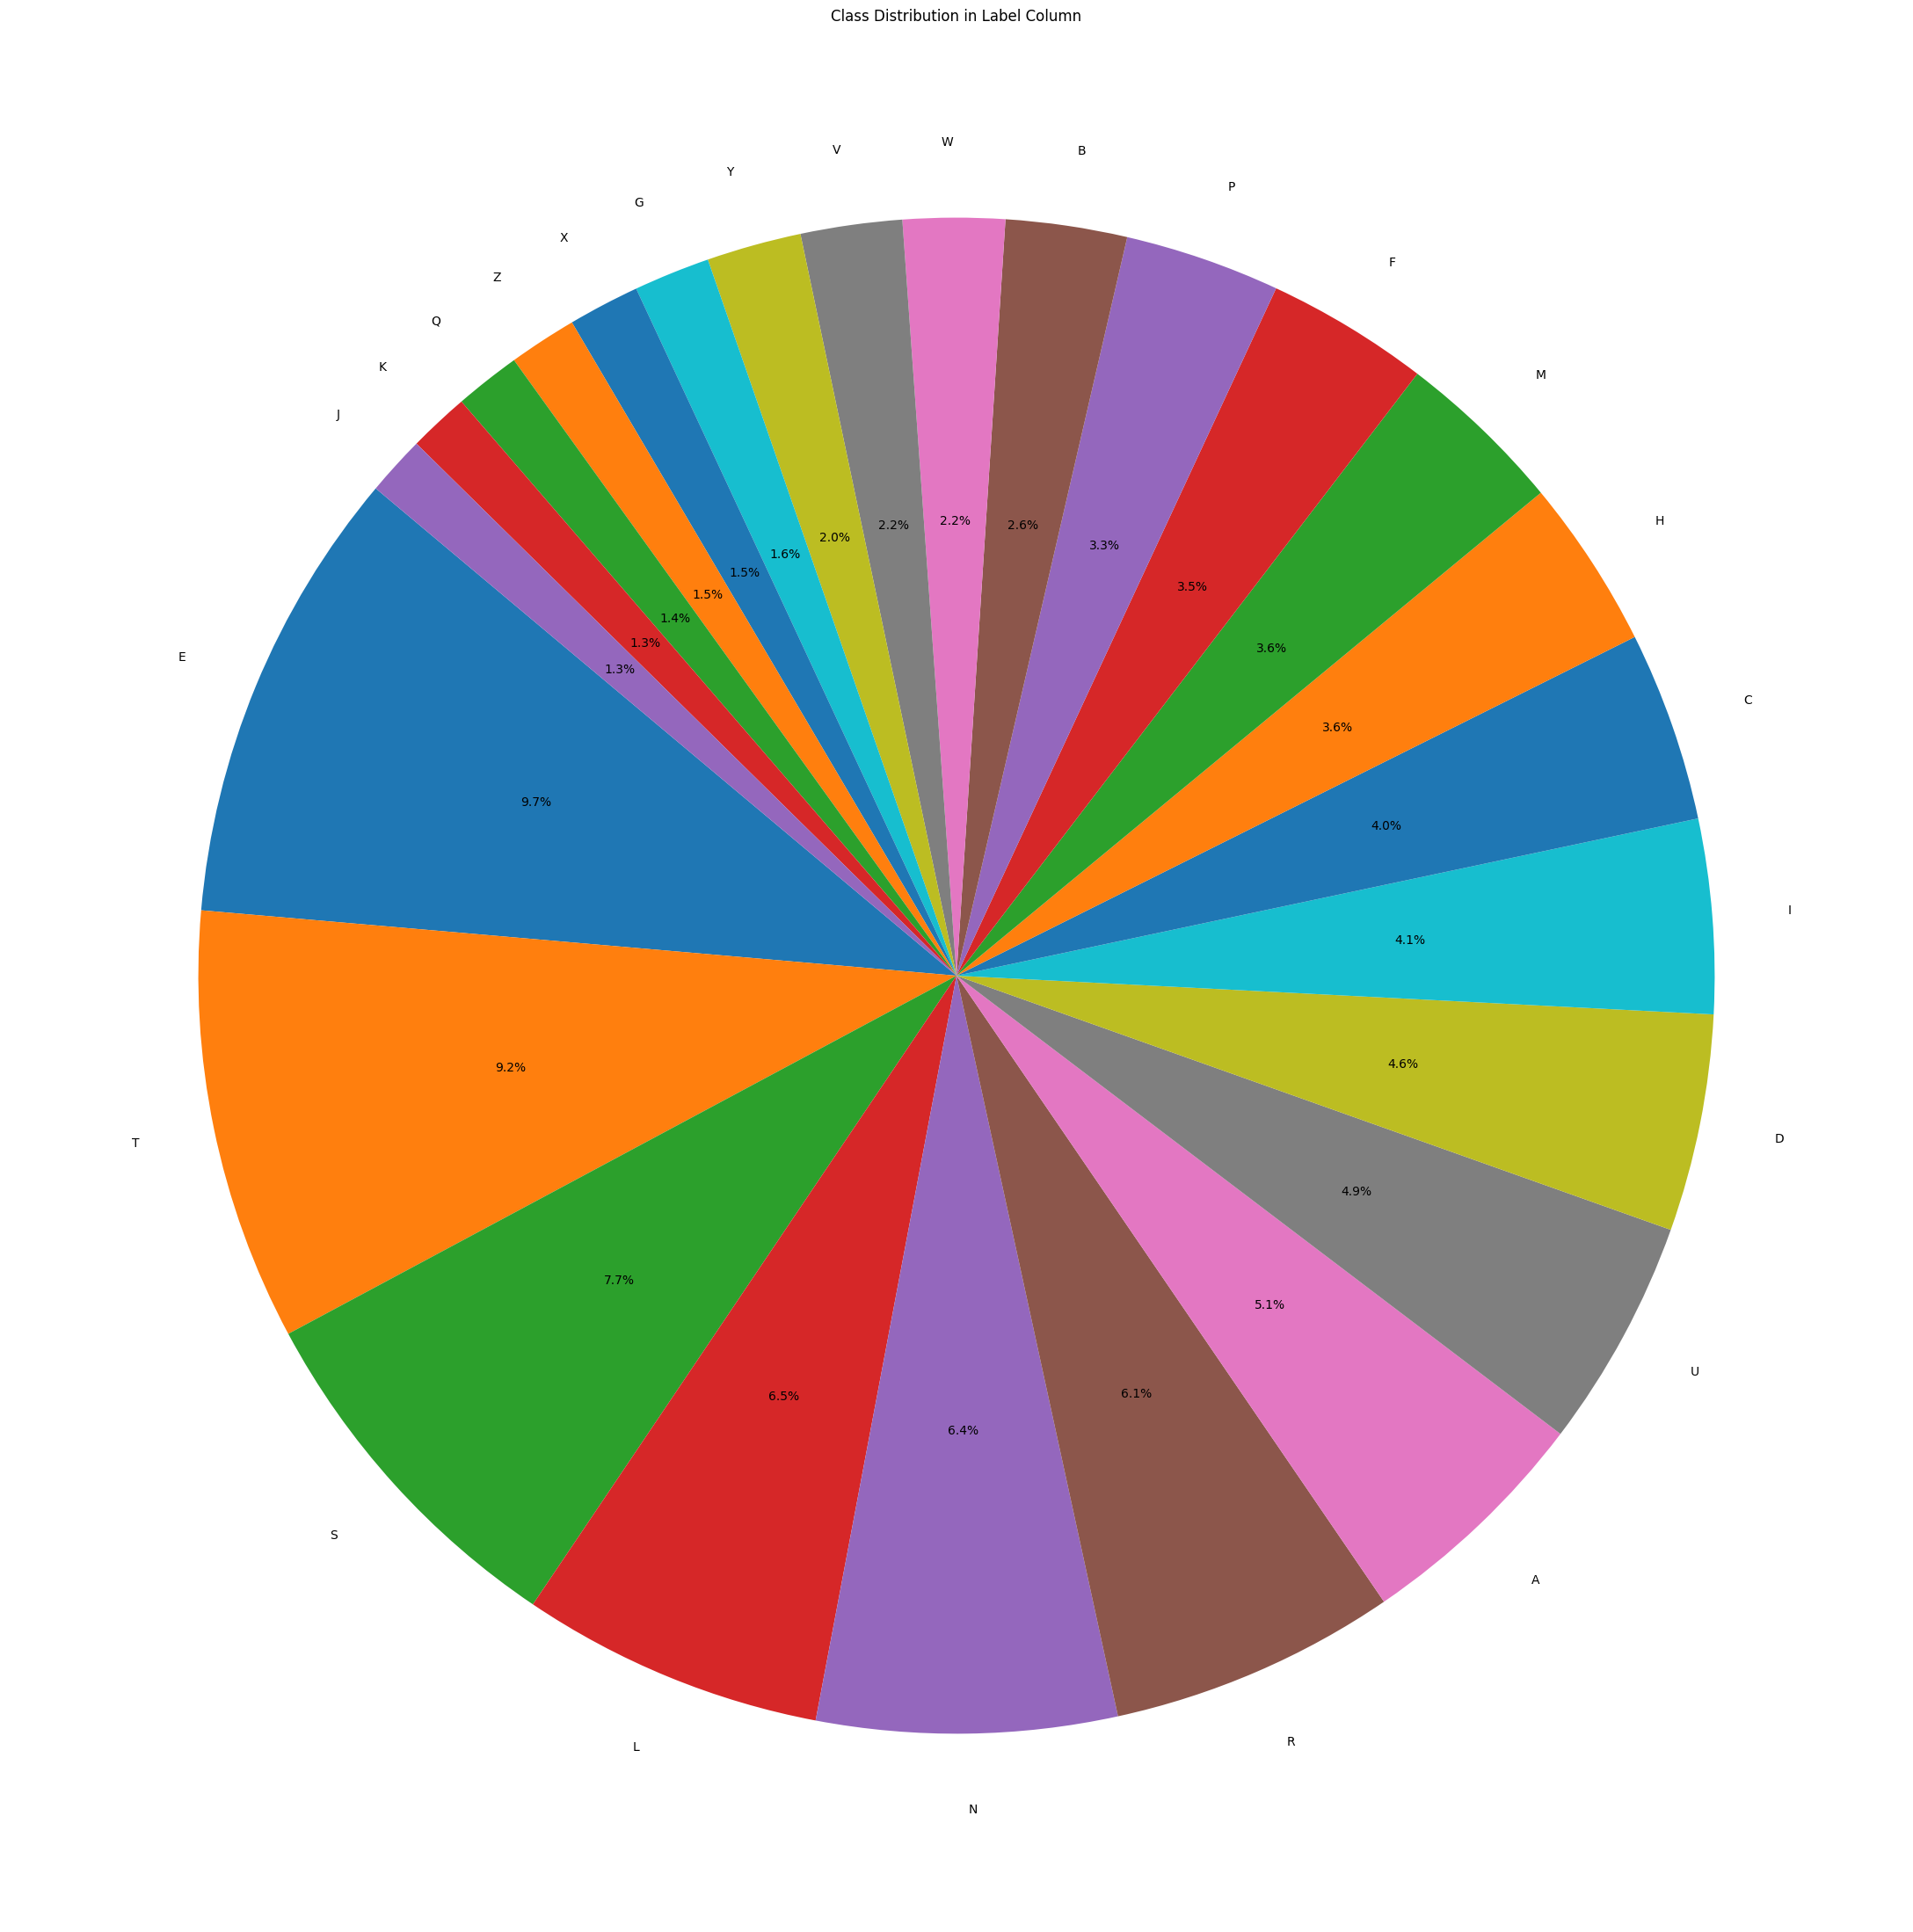

In [30]:
import matplotlib.pyplot as plt

label_counts = pd.DataFrame(train_data, columns=["image", "label"])["label"].value_counts()

# Plot the pie chart
plt.figure(figsize=(28, 28))
plt.pie(label_counts, labels=label_counts.index, autopct="%1.1f%%", startangle=140)
plt.title("Class Distribution in Label Column")
plt.show()

In [ ]:
df_train["label"].value_counts()

In [ ]:
df_train["label"].nunique()

In [ ]:
df_val["label"].nunique()

In [ ]:
import matplotlib.pyplot as plt

label_counts = pd.DataFrame(val_data, columns=["image", "label"])[
    "label"
].value_counts()

# Plot the pie chart
plt.figure(figsize=(28, 28))
plt.pie(label_counts, labels=label_counts.index, autopct="%1.1f%%", startangle=140)
plt.title("Class Distribution in Label Column")

plt.show()

In [ ]:
x = df_train.to_dict().items()

In [ ]:
x

In [ ]:
print(x)

In [ ]:
import random
random.shuffle(x)
# random.shuffle(df_val)

In [ ]:
df_train

In [ ]:
df_val["label"].value_counts()

In [ ]:
num_classes

In [ ]:
list[10]

In [ ]:
class HandWrittenCharaterDataset(Dataset):
    def __init__(self, df, transforms=None):
        self.df = df
        self.transforms = transforms

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image_path = row["image"]
        label = row["label"]
        image = Image.open(image_path).convert("L")
        if self.transforms:
            image = self.transforms(image)
        return image, torch.tensor(label)

In [ ]:
transform = transforms.Compose(
    [
        transforms.Grayscale(num_output_channels=1),
        transforms.Resize((32, 32)),
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ]
)

In [ ]:
# segmented_transform = SegmentedTransform(transform)
train_ds = HandWrittenCharaterDataset(df_train, transform)
val_ds = HandWrittenCharaterDataset(df_val, transform)

train_loader = DataLoader(
    train_ds, batch_size=batch_size, num_workers=8, pin_memory=True
)

val_loader = DataLoader(val_ds, batch_size=batch_size, num_workers=8, pin_memory=True)

In [ ]:
train_ds[10][0].shape

In [ ]:
class HandwritingOCR(nn.Module):

    def __init__(self, num_classes):
        super(HandwritingOCR, self).__init__()
        self.layer1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.layer2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.layer3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.fc = nn.Linear(128 * 4 * 4, num_classes)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = self.layer3(out)
        out = out.view(out.size(0), -1)
        out = self.fc(out)
        return out

In [ ]:
model = HandwritingOCR(num_classes=num_classes).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

In [ ]:
def train_fn(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    device,
    num_epochs=10,
    patience=5,
):
    best_val_loss = float("inf")
    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []
    epochs_no_improve = 0

    for epoch in range(num_epochs):
        print(f"Epoch {epoch+1}/{num_epochs}")
        print("-" * 10)

        # Training phase
        model.train()
        train_loss = 0.0
        train_acc = 0.0
        for inputs, labels in tqdm.tqdm(train_loader, total=len(train_loader)):
            inputs, labels = inputs.to(device, non_blocking=True), labels.to(
                device, non_blocking=True
            )

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * inputs.size(0)
            train_acc += (outputs.max(1)[1] == labels).sum().item()

        train_loss = train_loss / len(train_loader.dataset)
        train_acc = train_acc / len(train_loader.dataset)

        # Validation phase
        model.eval()
        val_loss = 0.0
        val_acc = 0.0
        with torch.no_grad():
            for inputs, labels in tqdm.tqdm(val_loader, total=len(val_loader)):
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                val_acc += (outputs.max(1)[1] == labels).sum().item()

        val_loss = val_loss / len(val_loader.dataset)
        val_acc = val_acc / len(val_loader.dataset)

        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

        # Save the model if the validation loss is the best so far
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model.state_dict(), "best_model-v9.pth")
            epochs_no_improve = (
                0  # Reset the counter when we get a better validation loss
            )
        else:
            epochs_no_improve += 1

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)

        # Plot the training and validation loss curves
        plt.figure(figsize=(10, 6))
        plt.plot(train_losses, label="Train Loss")
        plt.plot(val_losses, label="Validation Loss")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Training and Validation Loss")
        plt.legend()
        plt.savefig("loss_curves-v9.png")
        # plt.show()

        # Plot the training and validation accuracy curves
        plt.figure(figsize=(10, 6))
        plt.plot(train_accs, label="Train Accuracy")
        plt.plot(val_accs, label="Validation Accuracy")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.title("Training and Validation Accuracy")
        plt.legend()
        plt.savefig("accuracy_curves-v9.png")
        # plt.show()

        # Early stopping
        if epochs_no_improve == patience:
            print(f"Early stopping at epoch {epoch + 1}")
            break

    print(f"Best Val Loss: {best_val_loss:.4f}")
    torch.save(model.state_dict(), "model-v9.pth")


if __name__ == "__main__":
    train_fn(
        model,
        train_loader,
        val_loader,
        optimizer,
        criterion,
        device,
        num_epochs=num_epochs,
        patience=5,
    )

In [ ]:
def sort_contours(cnts, method="left-to-right"):
    reverse = False
    i = 0
    if method == "right-to-left" or method == "bottom-to-top":
        reverse = True
    if method == "top-to-bottom" or method == "bottom-to-top":
        i = 1
    boundingBoxes = [cv2.boundingRect(c) for c in cnts]
    (cnts, boundingBoxes) = zip(
        *sorted(zip(cnts, boundingBoxes), key=lambda b: b[1][i], reverse=reverse)
    )
    # return the list of sorted contours and bounding boxes
    return (cnts, boundingBoxes)


def get_letters(img):
    letters = []
    image = cv2.imread(img)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    ret, thresh1 = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)
    dilated = cv2.dilate(thresh1, None, iterations=2)

    cnts = cv2.findContours(dilated.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnts = imutils.grab_contours(cnts)
    cnts = sort_contours(cnts, method="left-to-right")[0]
    # loop over the contours
    for c in cnts:
        if cv2.contourArea(c) > 10:
            (x, y, w, h) = cv2.boundingRect(c)
            cv2.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 2)
        roi = gray[y : y + h, x : x + w]
        thresh = cv2.threshold(roi, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)[1]
        thresh = cv2.resize(thresh, (32, 32), interpolation=cv2.INTER_CUBIC)
        thresh = thresh.astype("float32") / 255.0
        thresh = np.expand_dims(thresh, axis=-1)
        thresh = thresh.reshape(1, 32, 32, 1)
        ypred = model.predict(thresh)
        ypred = LB.inverse_transform(ypred)
        [x] = ypred
        letters.append(x)
    return letters, image


# plt.imshow(image)
def get_word(letter):
    word = "".join(letter)
    return word


letter, image = get_letters(
    "../input/handwriting-recognition/train_v2/train/TRAIN_00003.jpg"
)
word = get_word(letter)
print(word)
plt.imshow(image)